In [1]:
source('../../../R/preamble.R')

# Fim Switch sequences
IR_sequence = 'TTGGGGCCA'

# Before and after the invertible element (minimal unique sequence in the genome)
before_irl = 'ATACAAGACAA'
before_irr = 'AAAGATGAAACAT'

# Read extracted reads that map to the Fim Switch

* **on:** whether the line refers to alignment to the ON position (TRUE) or the OFF position (FALSE)
* **score:** alignment score, 151 is a perfect alignment
* **top_strand:** whether the read was mapped to the top strand in the reference genome
* **start** and **end**: range of positions that were aligned, in the read and in the reference (which is the switch + 150 bp on each side)
* **mutations**: variants detected in the sequence, with position wrt the reference sequence (150 = beginning of the fimS)

In [2]:
files = list.files('../../../datasets/adhesion/fim_switch/FimS_Reads/', full.names = T)

# Read extracted reads that map to the Fim Switch
raw_reads = vroom(files) %>%
    rename(file = name) %>% 

    # Only use one side of the pair-end sequencing
    filter(grepl('R1', file)) %>% 

    mutate(
        name = str_split_i(file, '_', 1),
        # Sample names are <experiment><population><generation>, e.g. 'EB21' =
        # experiment E, population B, generation 21. NOTE: 'experiment' is the
        # first letter and is NOT a population: experiment E is the main 24-point
        # time course (all eight populations), while the A* and I* samples are
        # separate one-off sets. The population is the second letter (raw_pop).
        experiment = substr(name, 1, 1),
        raw_pop = substr(name, 2, 2),
        gen = substr(name, 3, 4),
        orientation = ifelse(on, 'OFF', 'ON'), # Because "on" means "OFF" in the python script, I inverted them by mistake
    ) %>%
    replace_na(mutations, 'None')

Rows: 124307 Columns: 11


── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): read_seq, mutations, name
dbl (6): read_id, score, read_start, read_end, ref_start, ref_end
lgl (2): on, top_strand



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Filter reads

In [3]:
min_bp = 4 # minimum of bp that must be read to infer orientation
min_alignment_length = 150

reads =
raw_reads %>%

    mutate(
        # Length of the mapped regions
        read_al_len = read_end - read_start,
        ref_al_len = ref_end - ref_start
        ) %>% 

    # For each read, only keep the orientation that got the best score
    group_by(file, name, read_id) %>%
    arrange(name, read_id, -score) %>% 
    filter(
        (n() == 1) | (max(score) - min(score) > min_bp),
        row_number() == 1,
    ) %>% ungroup() %>% 

    # Only keep reads that fully map to the reference
    filter(ref_al_len >= min_alignment_length)

## Correct cross-contaminations
**Permanent contaminations**
- EF05-06 to EH05-06
- EH12-13 to EE12-13
- EF13-14 to EG13-14

**Temporary contaminations**
Likely occured during the sequencing prep. Some are tiny.
- A10 to B11
- D21 to B21-22
- H6 to D6
- D22 to G22
- G19 to C19

# Permanent contaminations
* E before contamination by H is X
* G before contamination by F is Y
* H before contamination by F is Z

**I can't disentangle H, therefore I can't disentangle E either. Just ignore these populations. I can disentangle G, though.**

In [4]:
# Populations shown in every plot below. G and H are omitted (replaced by
# cross-contamination), E is omitted, and X/Y are the pre-contamination
# segments kept only for the disentangling above.
pops = c('A', 'B', 'C', 'D', 'F')

g_prosthetics = reads %>%
    filter(raw_pop == F & gen <= 13) %>%
    mutate(pop = 'G')

reads_disentangled =
reads %>%

    mutate(
        pop = case_when(
            raw_pop == 'E' & gen <= 12 ~ 'X',
            raw_pop == 'G' & gen <= 13 ~ 'Y',
            T ~ raw_pop
            )
        ) %>% 

    # Add a copy of F before it contaminated G
    rbind(g_prosthetics)

# Find which fraction is in which orientation

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by name, experiment, pop, gen, and
  orientation.
ℹ Output is grouped by name, experiment, pop, and gen.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(name, experiment, pop, gen, orientation))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.


Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2
3.5.0.”


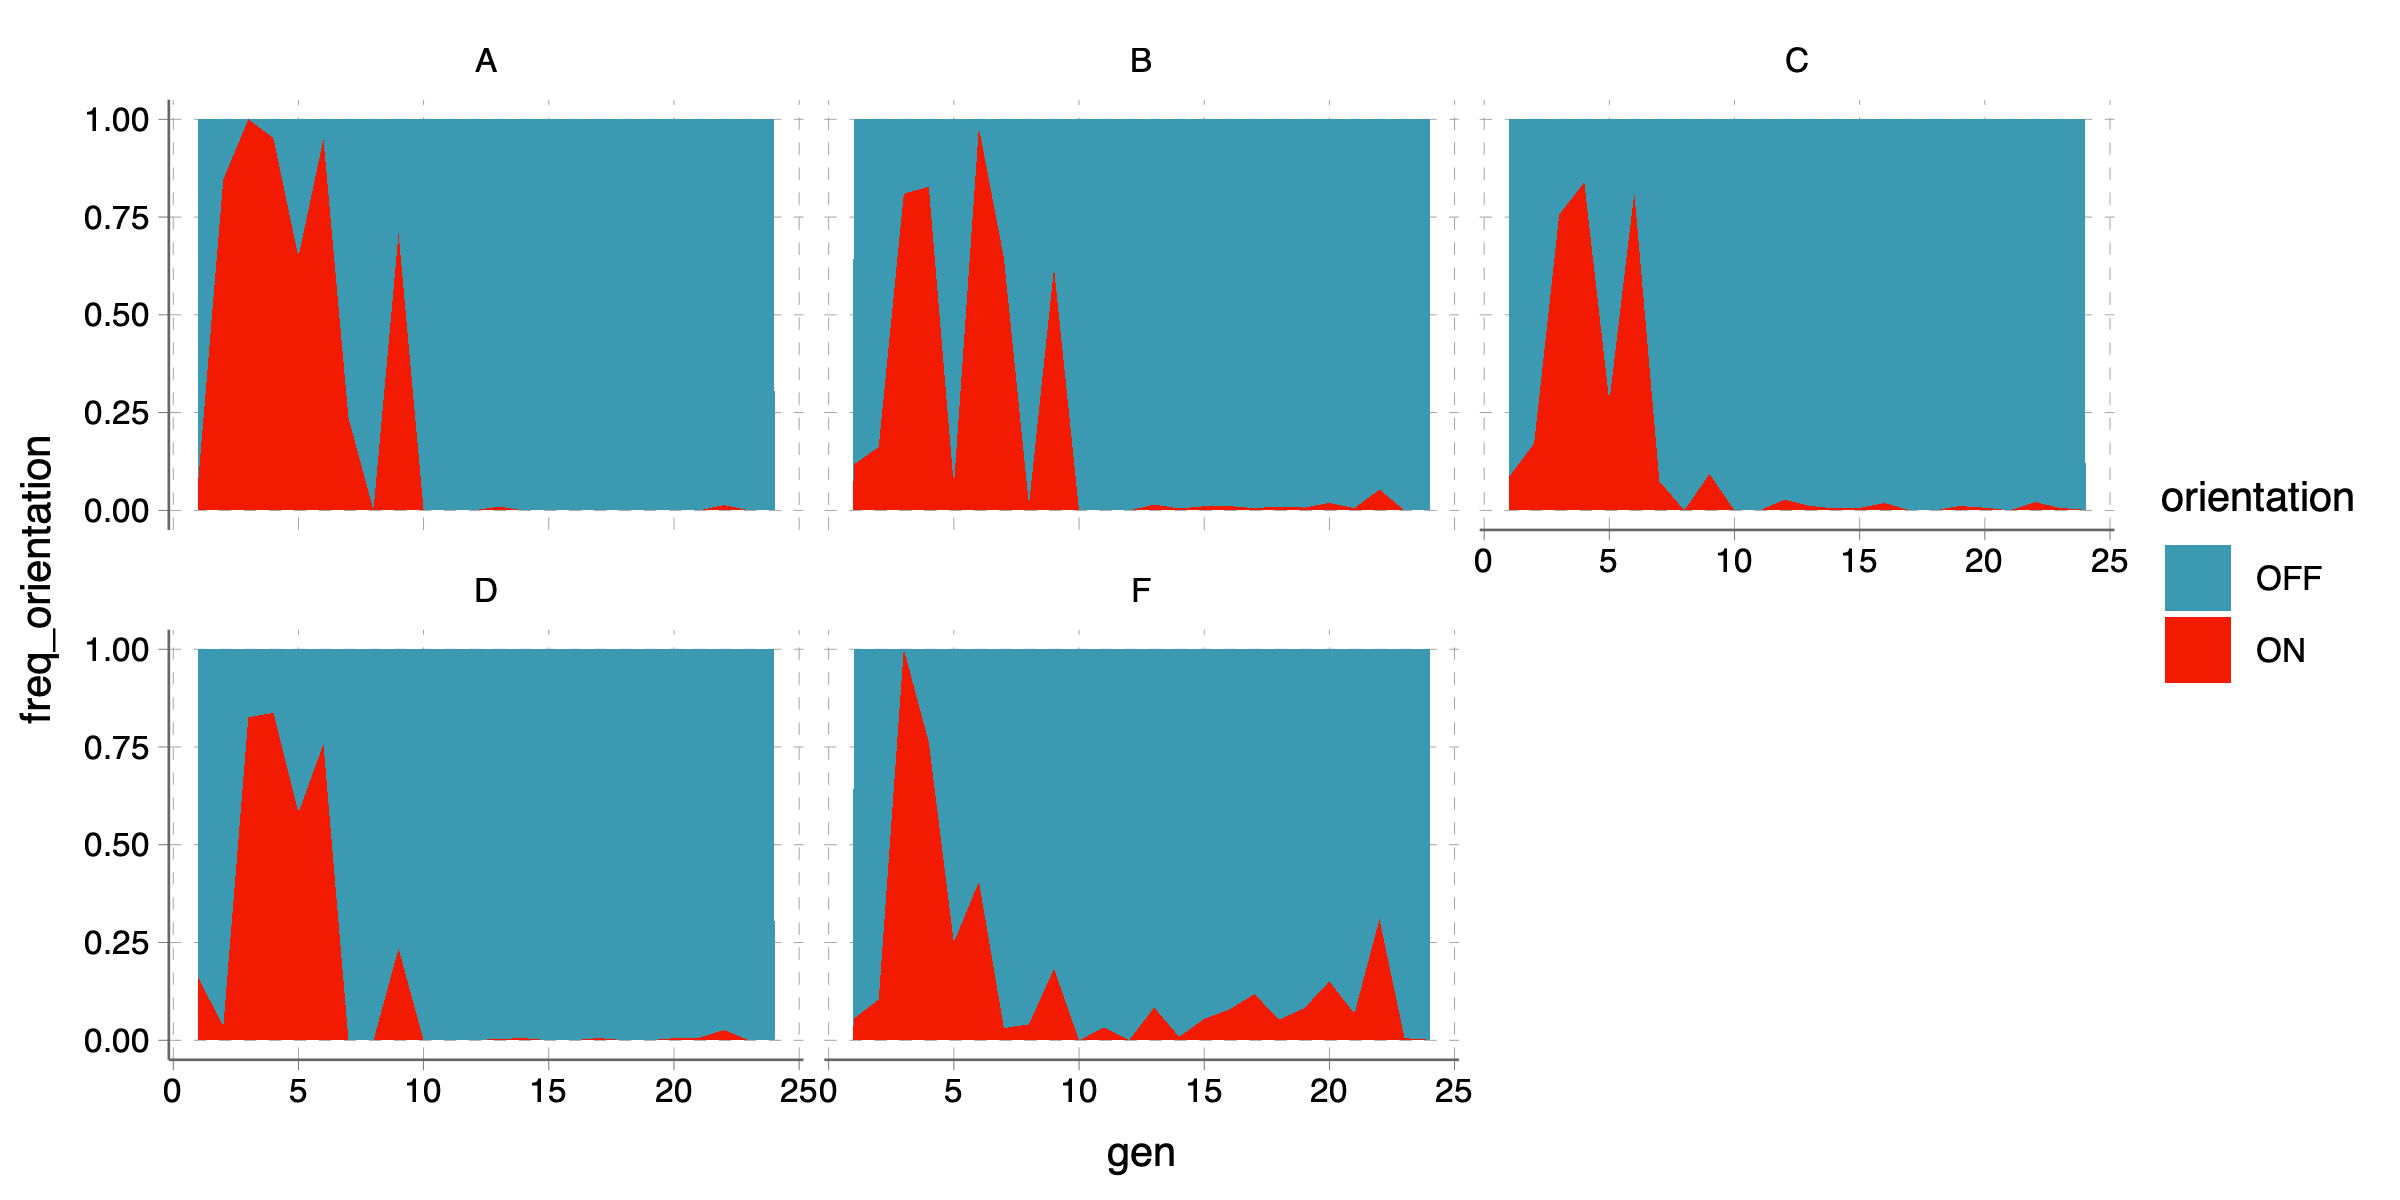

In [5]:
sample_to_fraction = 
    reads_disentangled %>%
    group_by(name, experiment, pop, gen, orientation) %>%
    summarise(
        n_orientation = n()
        ) %>%
    ungroup() %>% complete(nesting(name, experiment, pop, gen), orientation, fill = list('n_orientation'=0)) %>% 

    group_by(name, experiment, pop, gen) %>% 
    mutate(
        n_total = sum(n_orientation)
        ) %>% 

    ungroup() %>% mutate(gen = as.numeric(gen), freq_orientation = n_orientation / n_total) %>% 

    # Keep the main time course (all populations); see 'experiment' above -- not a population filter
    filter(experiment == 'E')#, !pop %in% c('E', 'H'))

size(4,8)

sample_to_fraction %>% filter(pop %in% pops) %>% 

# Keep the main time course (all populations); see 'experiment' above -- not a population filter
filter(experiment == 'E') %>% 
ggplot() + aes(gen, freq_orientation, fill = orientation, group = orientation) +
    facet_wrap(~pop) +

    geom_area()

# Find which mutations are real
Only keep mutations that are detected at least 5 times in at least one timepoint

In [6]:
min_detections = 5

pop_to_mutations =
reads_disentangled %>%
    select(name, experiment, pop, gen, mutations) %>% 
    separate_rows(mutations, sep = ', ') %>% 
    group_by(name, experiment, pop, gen, mutation = mutations) %>%
    summarise(detections = n()) %>%
    group_by(experiment, pop, mutation) %>% 
    summarise(max_detections = max(detections)) %>%
    ungroup() %>% 
    filter(max_detections >= min_detections, mutation != 'None') %>%
    mutate(pos = as.integer(substr(mutation, 2, nchar(mutation) - 1)))

pop_to_mutations %>% headn()

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by name, experiment, pop, gen, and mutation.
ℹ Output is grouped by name, experiment, pop, and gen.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(name, experiment, pop, gen, mutation))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by experiment, pop, and mutation.
ℹ Output is grouped by experiment and pop.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(experiment, pop, mutation))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


[1] 26


experiment,pop,mutation,max_detections,pos
<chr>,<chr>,<chr>,<int>,<int>
A,X,C368A,5,368
E,B,C453T,17,453
E,B,G160A,14,160


# Estimate mutant frequencies over time

In [7]:

mutant_frequencies =
    reads_disentangled %>%
    select(name, experiment, pop, gen, read_id, orientation, top_strand, read_start, read_end, ref_start, ref_end, mutations) %>% 

    # Get total reads
    #group_by(name, experiment, pop, gen) %>% mutate(n_total = n()) %>% ungroup() %>% 

    # Get all combinations of reads x mutations that exist in this population
    full_join(pop_to_mutations, relationship = "many-to-many") %>%

    # Calculate mutant frequencies based on whether a read could detect a mutation
    rowwise() %>% 
    mutate(
        detected = grepl(mutation, mutations),
        detectable = pos > ref_start & pos < ref_end
        ) %>% 

    group_by(name, experiment, pop, gen, orientation, mutation) %>%
    summarise(
        n_orientation = n(),
        n_detected = sum(detected),
        n_detectable = sum(detectable),
        ) %>%
    ungroup() %>% 
    mutate(
        n_inferred = n_orientation * n_detected / n_detectable,
        gen = as.numeric(gen)
    ) %>%
    filter(!is.na(mutation))

Joining with `by = join_by(experiment, pop)`


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by name, experiment, pop, gen, orientation,
  and mutation.
ℹ Output is grouped by name, experiment, pop, gen, and orientation.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(name, experiment, pop, gen, orientation, mutation))`
  for per-operation grouping (`?dplyr::dplyr_by`) instead.


# Only keep mutations that rise to a relevant amount

In [8]:
mutation_list = c("G160A", "C453T", "-461C", "G371T", "C163G", "A458C", "G450C", "-155G")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by pop, orientation, and gen.
ℹ Output is grouped by pop and orientation.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(pop, orientation, gen))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


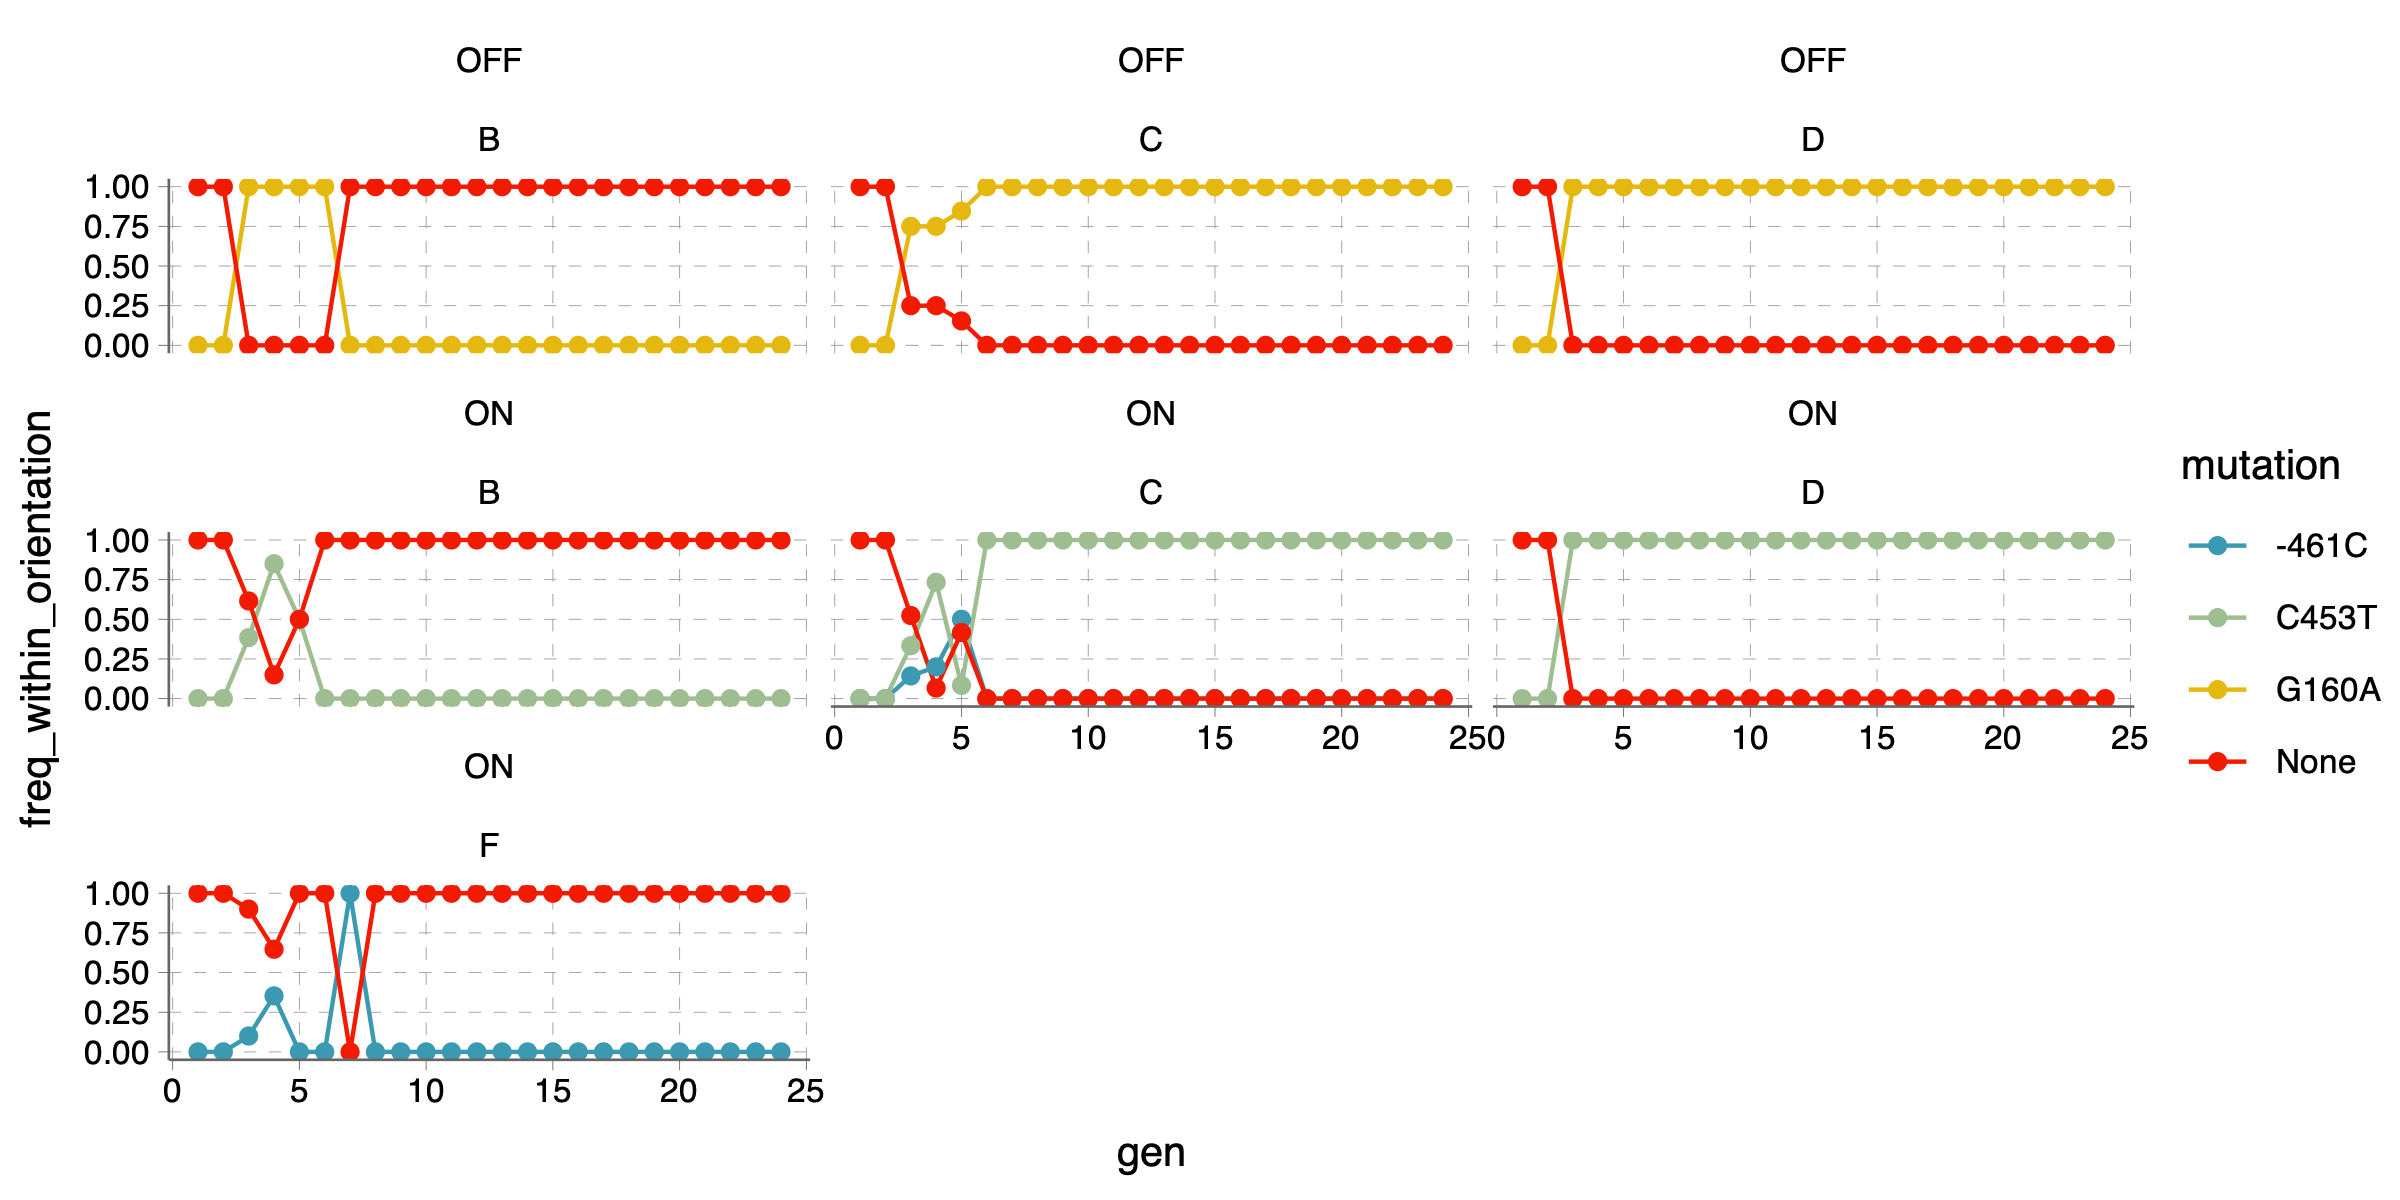

In [9]:
mutant_frequencies_filt = mutant_frequencies %>%

    # Cleanup dataset
    # Keep the main time course (all populations); see 'experiment' above -- not a population filter
    filter(experiment == 'E', n_detectable > 0) %>%
    #filter(gen != 9) %>% # sequenced later and prepared in a different way

    # Only keep mutations that reach 0.05
    group_by(pop, orientation, mutation) %>% 
    filter(mutation %in% mutation_list, max(n_detected) > 0) %>%
    ungroup() %>% 

    select(name, pop, gen, orientation, mutation, n_detectable, n_detected) %>% 
    
    # Remove the temporary cross-contamination from D21 to B21-22
    mutate(
        n_detected = ifelse(name %in% c('EB21', 'EB22') & mutation == 'G160A', 0, n_detected)
    ) %>% 

    # Calculate frequencies within the orientation
    mutate(freq_within_orientation = n_detected / n_detectable) %>% 
    complete(nesting(pop, orientation, mutation), gen = 1:24, fill = list('freq_within_orientation' = NA)) %>%
    filter(!(pop == 'X' & gen > 12), !(pop == 'Y' & gen > 13)) %>% # trim the replaced populations
    fill(freq_within_orientation) %>% 

    # Clamp fixed mutants to frequency 1 (within orientation)
    group_by(pop, orientation, mutation) %>% arrange(gen) %>% 
    mutate(
        fixed = gen > min(gen[freq_within_orientation == 1], Inf) & freq_within_orientation > 0.9,
        freq_within_orientation = ifelse(fixed, 1, freq_within_orientation)
        ) %>% 
    ungroup() %>% 

    # Merge -155G and -461C in Y together, as they co-occur
    mutate(mutation = ifelse(pop == 'Y' & mutation == '-155G', '-155G, -461C', mutation)) %>% 
    filter(!(pop == 'Y' & mutation == '-461C')) %>%
    
    select(pop, orientation, mutation, gen, freq_within_orientation)

# Generate lines for the clade without mutations
nonmutant_frequencies_filt = mutant_frequencies_filt %>%

    group_by(pop, orientation, gen) %>%
    summarise(
        mutation = 'None',
        freq_within_orientation = 1 - sum(freq_within_orientation)
        ) %>%
    ungroup()

# Merge
mutant_frequencies_filt = rbind(mutant_frequencies_filt, nonmutant_frequencies_filt)

mutant_frequencies_filt %>% filter(pop %in% pops) %>% 

    #filter(orientation == 'OFF') %>% 

    ggplot() + aes(gen, freq_within_orientation, col = mutation, group = paste(orientation, mutation)) +
    facet_wrap(orientation~pop) +
    geom_line() + geom_point()

Joining with `by = join_by(pop, gen, orientation)`


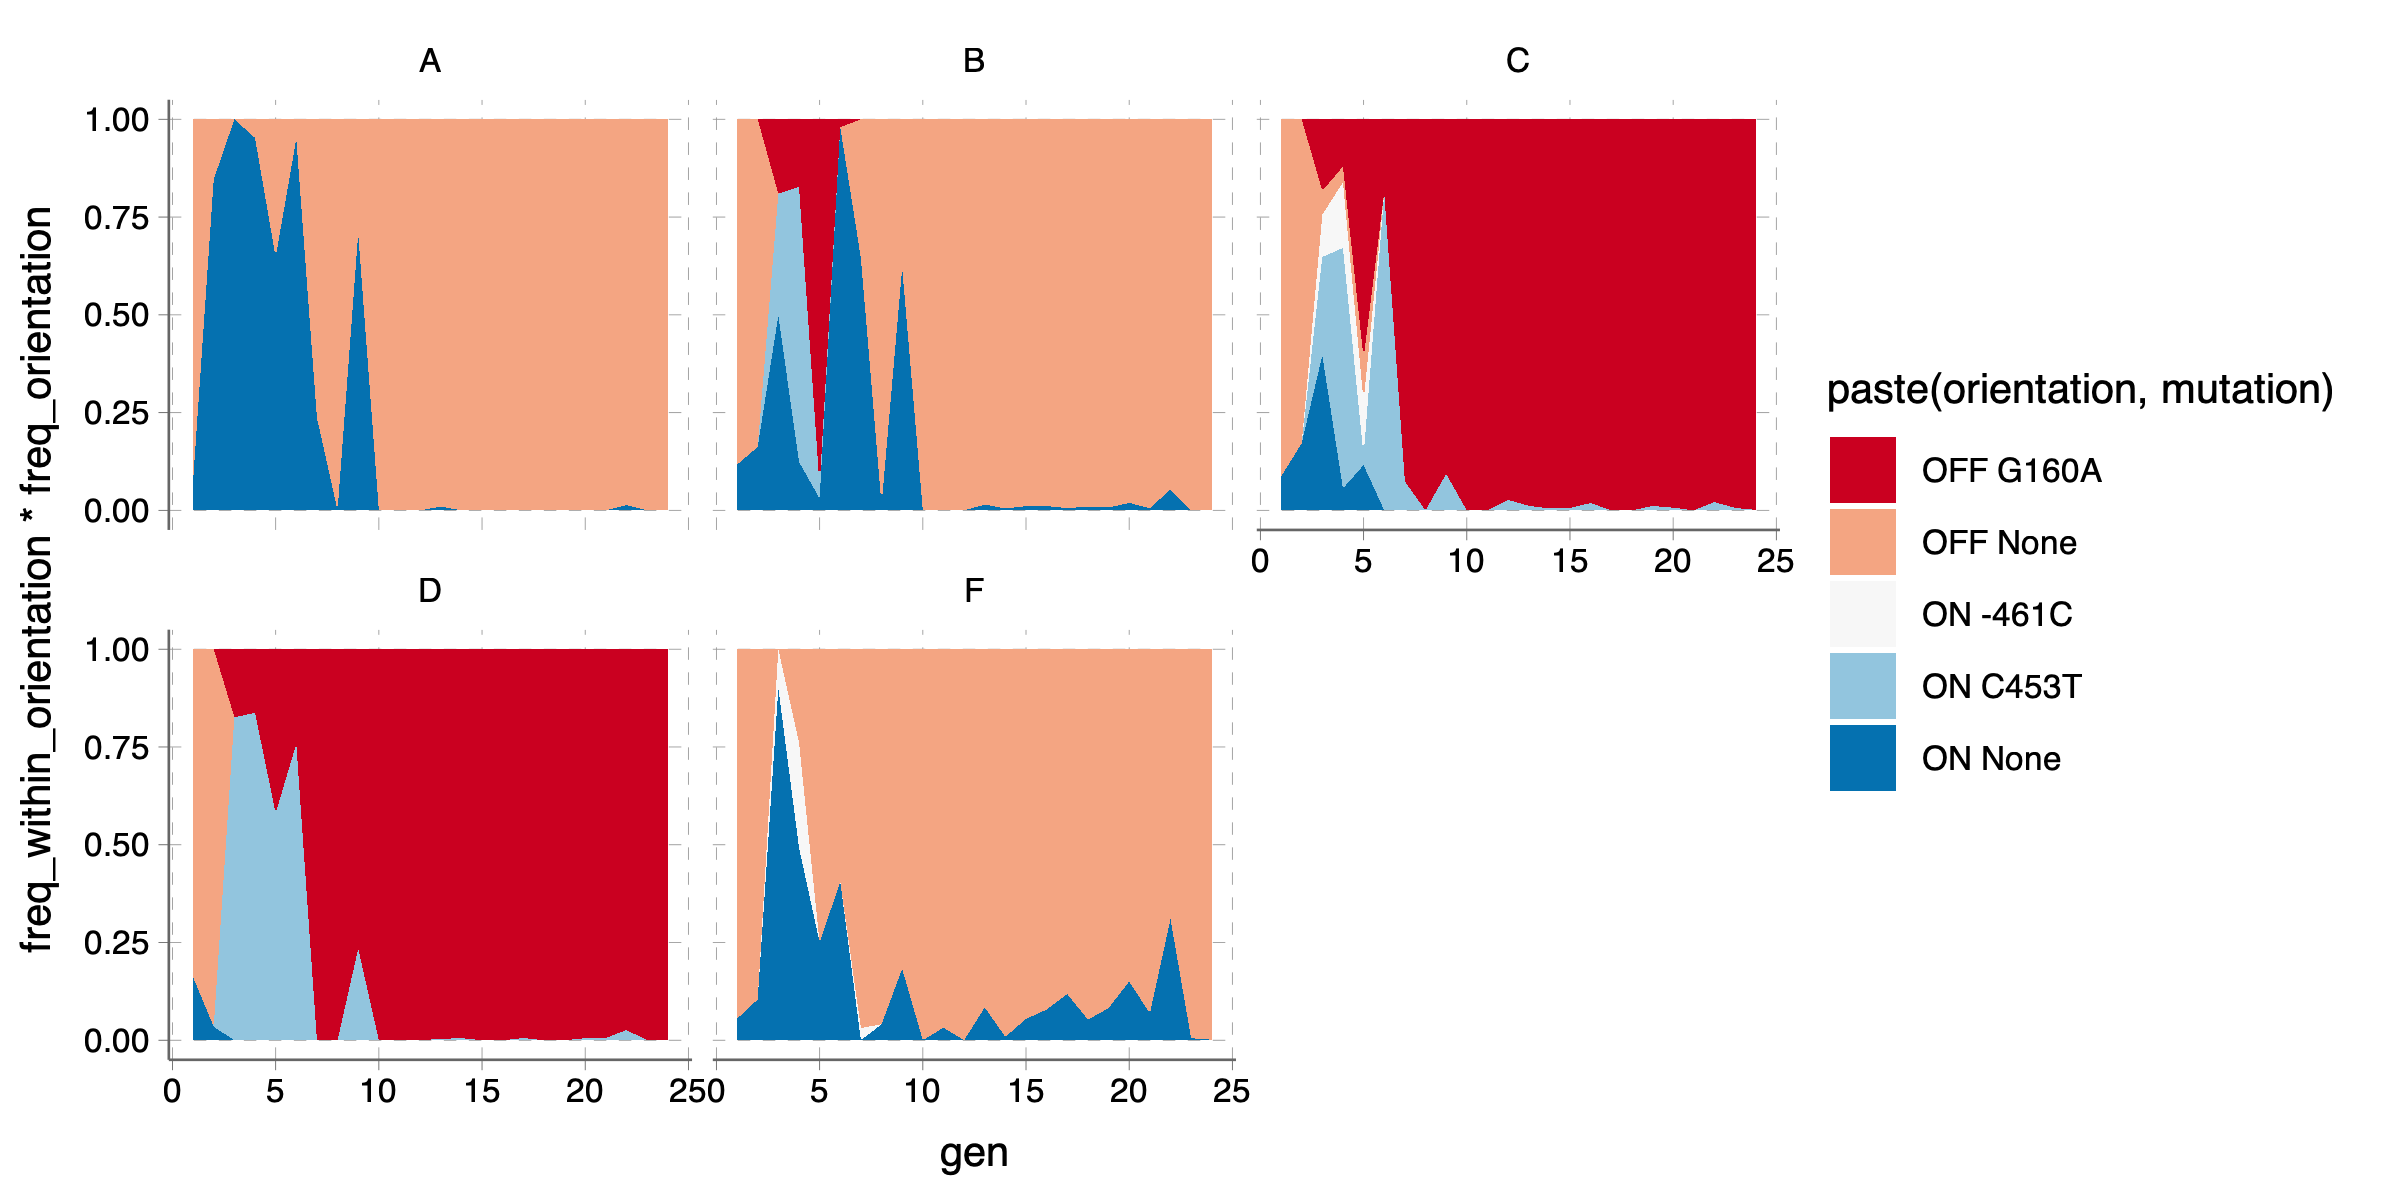

In [10]:
genotypes_over_time =

    sample_to_fraction %>%
    #filter(gen != 9) %>% 

    select(name, pop, gen, orientation, freq_orientation) %>%

    # Add the mutant breakdown
    left_join(mutant_frequencies_filt) %>% 
    replace_na(mutation, 'None') %>% 
    replace_na(freq_within_orientation, 1)

genotypes_over_time %>% write.tsv('../../../datasets/adhesion/fim_switch/genotypes_over_time.tsv')

genotypes_over_time %>% filter(pop %in% pops) %>% 

ggplot() + aes(gen, freq_within_orientation * freq_orientation, fill = paste(orientation, mutation), group = paste(orientation, mutation)) +
    facet_wrap(~pop) +
    scale_fill_brewer(palette = 'RdBu') +
    geom_area()

In [11]:
mutation_identities = c(
    'G160A' = 'IR+2 AAC→AGC', # 2 bp after the IR
    '-155G' = 'IRR ΔG',
    '-461C' = 'IRL ΔG',
    '-155G, -461C' = 'IRR+IRL ΔG',
    'C453T' = 'IR+2 AAC→AGC'
)

In [12]:
library(colorspace)

lighten <- function(color, factor = 0.5) {
    rgb_col <- col2rgb(color)
    rgb_col <- rgb_col + (255 - rgb_col) * factor
    rgb(rgb_col[1], rgb_col[2], rgb_col[3], maxColorValue = 255)
}

manual_colors = c(
    'ON_None' = lighten(pal[5], 0.4),
    'ON_C453T' = lighten(pal[5], 0.2),
    'ON_-461C' = lighten(pal[5], 0),
    
    'OFF_None' = lighten(pal[1], 0.4),
    'OFF_G160A' = lighten(pal[1], 0.1),
    'OFF_-155G, -461C' = lighten(pal[1], 0)
    )

In [13]:
plot_labels = read.csv(text = 'pop, x, y, l
A, 10, 0.21, ON
A, 40, 0.5, OFF
B, 16, 0.16, ON
B, 40, 0.5, OFF
C, 7, 0.12, ON
C, 40, 0.5, OFF*
D, 11, 0.25, ON*
D, 40, 0.5, OFF*
F, 9, 0.16, ON
F, 40, 0.5, OFF
')

Warning message in geom_line(data = sample_to_fraction %>% filter(orientation == :
“Ignoring unknown aesthetics: fill”


Warning message in geom_text(aes(group = T, fill = T, col = T, label = l), fill = b, :
“Ignoring unknown parameters: `fill`”


Warning message in geom_text(aes(group = T, fill = T, col = T, label = l), fill = b, :
“Ignoring unknown aesthetics: fill”


Warning message in plot_theme(plot):
“The `panel.margin.y` theme element is not defined in the element hierarchy.”


Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_area()`).”


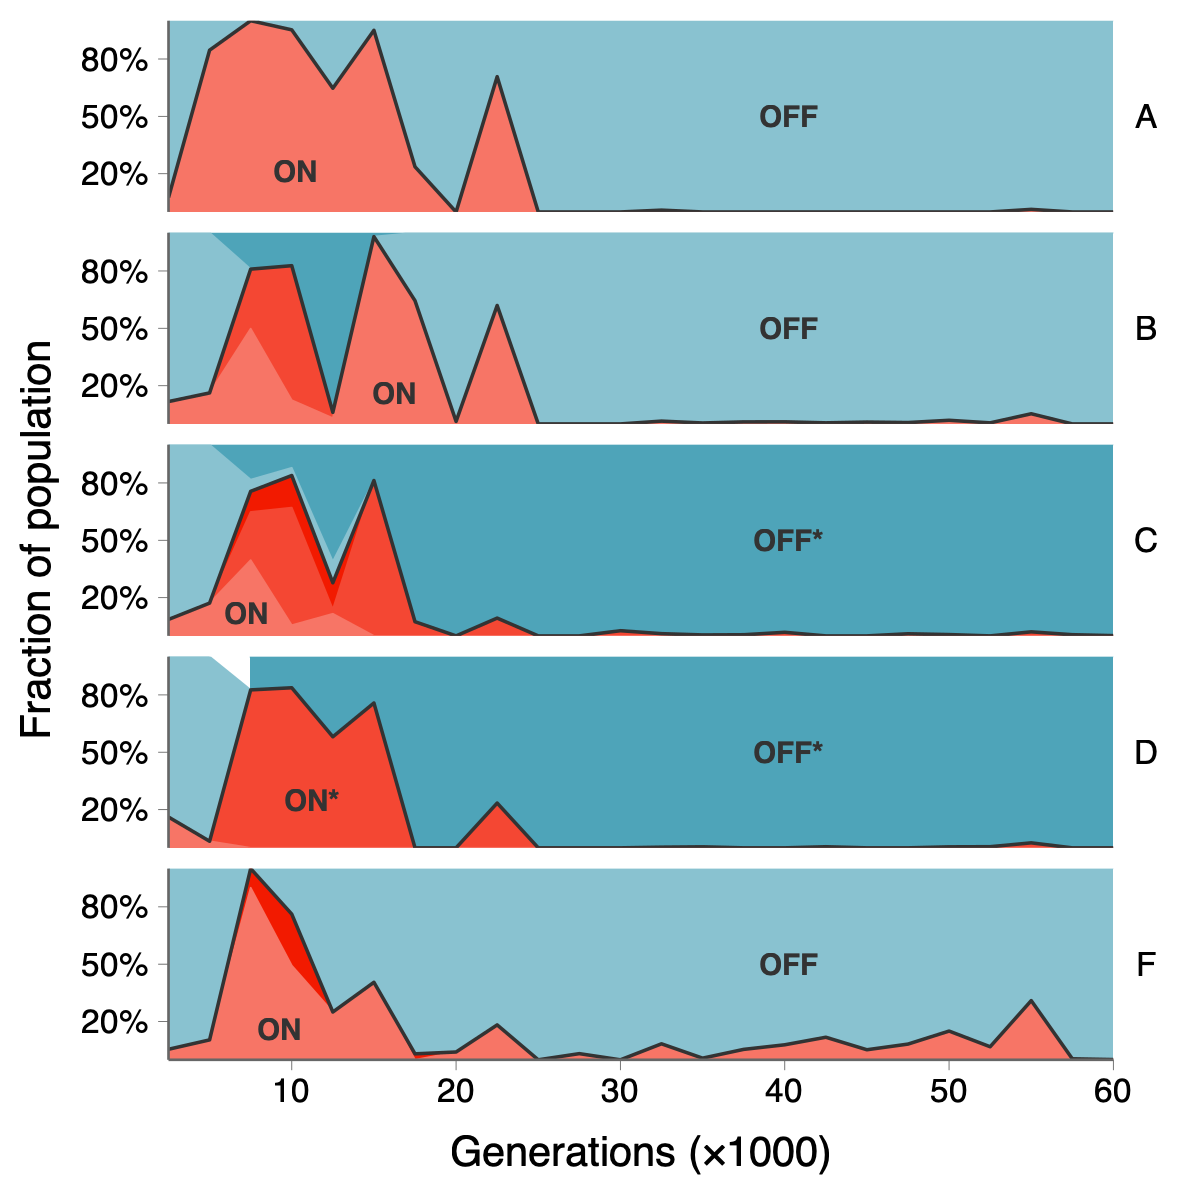

In [14]:


size(4, 4)

fims_plotting_data =
genotypes_over_time %>% 

    mutate(
        mut_id = mutation_identities[mutation],
        geno = paste(orientation, mutation, sep = '_'),
        x = gen * 2.5,
        y = freq_within_orientation * freq_orientation
    ) %>% 
    filter(pop %in% pops)

fims_plotting_data %>% 

ggplot() + aes(x, y, fill = geno, col = geno, group = geno) + nl +

    #facet_wrap(~pop) +
    facet_grid(pop ~ .) +

    xcont(2.5, 60, ) +
    ycont(0, 1, label = percent, breaks = seq(0.2, 0.8, 0.3)) +
    scale_fill_manual(values = manual_colors) +
    scale_color_manual(values = manual_colors) +

    geom_area(
        lwd = 0.2, 
        #col = 'grey90'
    ) +

    theme(
        strip.text.y.right = element_text(angle = 0),
        panel.grid.major = eb,
        panel.margin.y = unit(0.2, "lines"),
    ) +

    geom_line(
        data = sample_to_fraction %>% filter(orientation == 'ON', pop %in% pops),
        aes(x = gen * 2.5, y = freq_orientation, group = pop, fill = pop),
        col = 'grey20', lwd = 0.4
        ) +

    geom_text(
        aes(group = T, fill = T, col = T, label = l), 
        fill = b, col = 'grey20', size = 2.5, fontface = 'bold',
        data = plot_labels,
    ) +

    labs(x = 'Generations (×1000)', y = 'Fraction of population')

In [15]:
# Export for montages
fims_plotting_data %>% write.tsv('../../../datasets/adhesion/fim_switch/fims_plotting_data.tsv')